# UK wind forecast error: January 2026

**Business question.** Our team buys power on the day-ahead market: *power to buy ≈ demand − expected wind*.
If wind comes in below the forecast, we are short and must buy the gap at short notice, usually at a worse price.
How wrong are the wind forecasts we would have had at decision time, and how much safety margin should we hold?

**Data.** Elexon BMRS, all times UTC:
- *Actuals*: `FUELHH` national wind generation, every 30 minutes (1,488 periods).
- *Forecasts*: `WINDFOR` national wind forecast, hourly targets, published about 8 times a day.

**Method.** For a horizon *H*, each hour uses the latest forecast published at least *H* hours before it,
which is exactly what the web app shows. The selection and metric code is imported from `backend/app/`, not
re-implemented here. Error = forecast − actual: **positive means forecast wind did not arrive**, so we under-bought.

**Run it:** `pip install -r analysis/requirements.txt`, then open this notebook from the repo root or `analysis/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# Make backend/app importable whether the notebook runs from the repo root or analysis/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend" / "app").is_dir())
sys.path.insert(0, str(ROOT / "backend"))

from app import config
from app.data_store import read_frame
from app.forecast_logic import build_comparison
from app.metrics import compute_metrics, error_by_horizon

actuals = read_frame(config.ACTUALS_PATH)
forecasts = read_frame(config.FORECASTS_PATH)
START, END = config.TARGET_START, config.TARGET_END

DAY_AHEAD_H = 24          # representative day-ahead decision horizon
DECISION_WINDOW = (12, 36)  # the auction closes ~midday the day before: 12-36h ahead
COLORS = {"actual": "#2563eb", "forecast": "#16a34a", "mae": "#7c3aed", "p90": "#ea580c", "bias": "#64748b"}

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
gw = lambda mw: mw / 1000
key_numbers = {}  # exported at the end for the README and the client pitch

## 1. Data overview

,value
Actual half-hours,1488
Missing half-hours,0
Hourly forecast targets,744
Forecast runs (publish times),264
Forecasts per target (median),16
Forecast horizon range (h),0.5 to 47.6


,min,10%,50%,mean,90%,max
Actual wind (GW),1.7,5.62,12.14,11.58,16.44,17.8


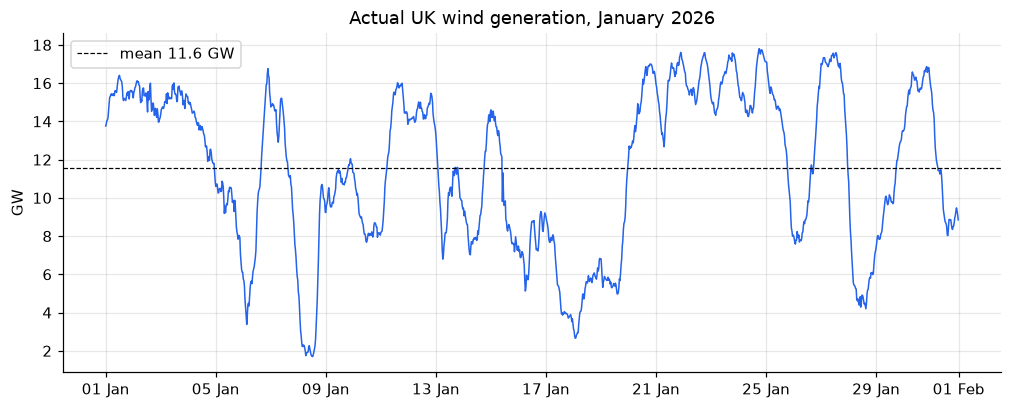

In [2]:
forecasts["horizon_h"] = (forecasts["startTime"] - forecasts["publishTime"]).dt.total_seconds() / 3600
expected_periods = pd.date_range(START, END, freq="30min")
per_target = forecasts.groupby("startTime").size()

overview = pd.Series({
    "Actual half-hours": len(actuals),
    "Missing half-hours": len(expected_periods.difference(actuals["startTime"])),
    "Hourly forecast targets": forecasts["startTime"].nunique(),
    "Forecast runs (publish times)": forecasts["publishTime"].nunique(),
    "Forecasts per target (median)": int(per_target.median()),
    "Forecast horizon range (h)": f'{forecasts["horizon_h"].min():.1f} to {forecasts["horizon_h"].max():.1f}',
}, name="value")
display(overview.to_frame())

wind = gw(actuals["generation"])
stats = wind.describe(percentiles=[0.1, 0.5, 0.9])[["min", "10%", "50%", "mean", "90%", "max"]].round(2)
display(stats.rename("Actual wind (GW)").to_frame().T)
key_numbers.update(actual_min_gw=stats["min"], actual_mean_gw=stats["mean"], actual_max_gw=stats["max"],
                   actual_p10_gw=stats["10%"])

fig, ax = plt.subplots()
ax.plot(actuals["startTime"], wind, color=COLORS["actual"], lw=1)
ax.axhline(stats["mean"], color="k", ls="--", lw=0.8, label=f'mean {stats["mean"]:.1f} GW')
ax.set(title="Actual UK wind generation, January 2026", ylabel="GW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend();

**Takeaway.** The data is complete: no missing half-hours, and every hour of January has about 16 forecasts
to choose from. Wind averaged **11.6 GW** but ranged from **1.7 to 17.8 GW**, often swinging by more than 10 GW
within two days (e.g. 5–7 Jan). In 90% of half-hours wind delivered at least **5.6 GW**. That is the "reliable
wind" floor we could count on almost regardless of the forecast.

## 2. Forecast vs actual at the day-ahead horizon

The day-ahead auction closes around midday the day before delivery, so purchase decisions use forecasts
roughly **12–36 hours** old. We use **24h** as the headline horizon and show 12h and 36h for context.

,12h,24h,36h
count,744.00,744.00,744.00
mae (GW),1.90,2.05,2.26
rmse (GW),2.38,2.52,2.75
bias (GW),1.70,1.85,1.95
p50_abs_error (GW),1.52,1.73,2.02
p90_abs_error (GW),3.90,4.13,4.26
p99_abs_error (GW),6.22,6.29,6.74
mape (%),17.60,20.50,23.90
max_over_forecast (GW),6.88,6.80,8.66
max_under_forecast (GW),3.08,2.66,2.77


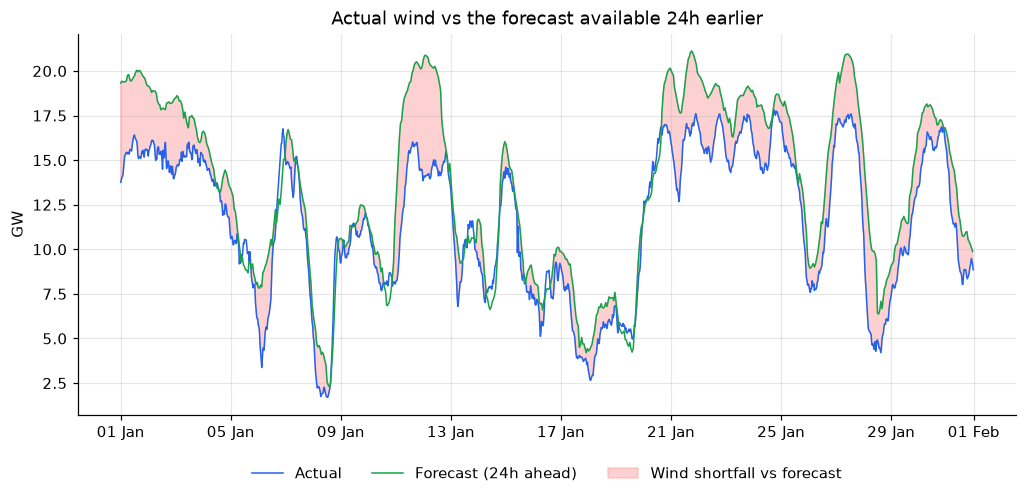

In [3]:
def comparison(h, start=START, end=END):
    """Hours with a qualifying forecast at horizon h (half-hours have no hourly forecast)."""
    return build_comparison(actuals, forecasts, h, start, end).dropna(subset=["forecast"])

c24 = comparison(DAY_AHEAD_H)
table = pd.DataFrame({f"{h}h": compute_metrics(comparison(h)) for h in (12, DAY_AHEAD_H, 36)})
mw_rows = ["mae", "rmse", "bias", "p50_abs_error", "p90_abs_error", "p99_abs_error", "max_over_forecast", "max_under_forecast"]
display_table = table.copy()
display_table.loc[mw_rows] = (table.loc[mw_rows].astype(float) / 1000).round(2)
display_table.loc["mape"] = table.loc["mape"].astype(float).round(1)
display(display_table.rename(index=lambda r: f"{r} (GW)" if r in mw_rows else ("mape (%)" if r == "mape" else r)))

m24 = table[f"{DAY_AHEAD_H}h"]
key_numbers.update(h24_mae_gw=round(gw(m24["mae"]), 2), h24_rmse_gw=round(gw(m24["rmse"]), 2),
                   h24_bias_gw=round(gw(m24["bias"]), 2), h24_p90_abs_gw=round(gw(m24["p90_abs_error"]), 2),
                   h24_mape_pct=round(m24["mape"], 1))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(actuals["startTime"], gw(actuals["generation"]), color=COLORS["actual"], lw=1, label="Actual")
ax.plot(c24["startTime"], gw(c24["forecast"]), color=COLORS["forecast"], lw=1, label="Forecast (24h ahead)")
ax.fill_between(c24["startTime"], gw(c24["actual"]), gw(c24["forecast"]), where=c24["error"] > 0,
                color="#fca5a5", alpha=0.5, label="Wind shortfall vs forecast")
ax.set(title="Actual wind vs the forecast available 24h earlier", ylabel="GW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False);

**Takeaway.** At the day-ahead horizon (24h) the forecast misses by **2.05 GW** in a typical hour, about 18% of
average output. In 1 hour in 10 the miss exceeds **4.1 GW**. The chart shows the key problem: the shortfall
(red) is almost always on the same side. **The forecast promised more wind than arrived**, by **1.85 GW** on
average, and that is the expensive direction for us. Within the realistic 12–36h decision window the typical error
only moves from 1.90 to 2.26 GW, so *when* in that window we decide matters far less than *how* we use the forecast.

## 3. Does error grow with horizon?

Every whole hour from 0h to 48h, over the whole month.

,mae (GW),rmse (GW),bias (GW),p90_abs_error (GW),count
horizon,,,,,
0.0,1.79,2.28,1.59,3.76,744
6.0,1.87,2.35,1.68,3.88,744
12.0,1.90,2.38,1.70,3.90,744
24.0,2.05,2.52,1.85,4.13,744
36.0,2.26,2.75,1.95,4.26,744
42.0,2.31,2.84,1.94,4.48,744


horizon,42.0,43.0,44.0,45.0,46.0,47.0,48.0
hours with a forecast (of 744),744,744,713,621,465,217,0


MAE grows 29% from 0h to 42h; on average bias is 88% of MAE.


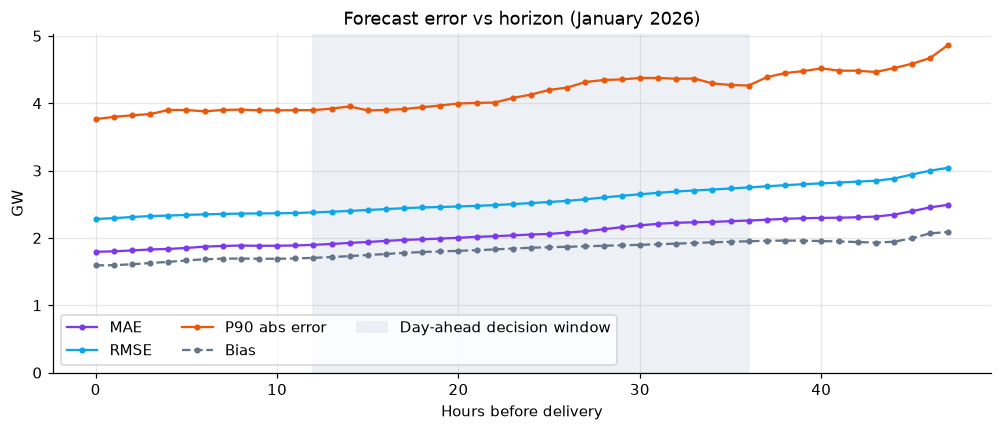

In [4]:
by_h = pd.DataFrame(error_by_horizon(actuals, forecasts, START, END, horizons=range(0, 49))).set_index("horizon")
has_data = by_h["count"] > 0

fig, ax = plt.subplots()
for col, name in [("mae", "MAE"), ("rmse", "RMSE"), ("p90_abs_error", "P90 abs error"), ("bias", "Bias")]:
    color = {"mae": COLORS["mae"], "p90_abs_error": COLORS["p90"], "bias": COLORS["bias"]}.get(col, "#0ea5e9")
    ax.plot(by_h.index[has_data], gw(by_h.loc[has_data, col]), marker="o", ms=3, label=name, color=color,
            ls="--" if col == "bias" else "-")
ax.axvspan(*DECISION_WINDOW, color="#e2e8f0", alpha=0.6, label="Day-ahead decision window")
ax.set(title="Forecast error vs horizon (January 2026)", xlabel="Hours before delivery", ylabel="GW", ylim=(0, None))
ax.legend(ncol=3);

summary = by_h.loc[[0, 6, 12, 24, 36, 42], ["mae", "rmse", "bias", "p90_abs_error"]].pipe(gw).round(2)
summary["count"] = by_h["count"]
display(summary.rename(columns=lambda c: f"{c} (GW)" if c != "count" else c))
display(by_h.loc[42:48, ["count"]].T.rename(index={"count": "hours with a forecast (of 744)"}))

growth = by_h.loc[42, "mae"] / by_h.loc[0, "mae"] - 1
share_bias = (by_h.loc[has_data, "bias"] / by_h.loc[has_data, "mae"]).mean()
print(f"MAE grows {growth:.0%} from 0h to 42h; on average bias is {share_bias:.0%} of MAE.")
key_numbers.update(mae_0h_gw=round(gw(by_h.loc[0, "mae"]), 2), mae_42h_gw=round(gw(by_h.loc[42, "mae"]), 2),
                   mae_growth_0_to_42h_pct=round(growth * 100))

**Takeaway.** Error does grow with horizon, but slowly: MAE rises **29%**, from **1.79 GW** at 0h to **2.31 GW**
at 42h. More striking, the forecast is about **1.6 GW too high even half an hour before delivery**, and bias
makes up about 88% of the typical error at every horizon. So the error is mostly a **systematic offset, not
growing uncertainty**. Waiting for a fresher forecast would not fix it; correcting the offset would (section 6).

*Coverage note:* the app only uses forecasts made at most 48h ahead, and runs are published at :30, so from
about 44h fewer hours have a qualifying forecast, and at exactly 48h none do. The web app reports this
rather than showing misleading numbers.

## 4. Error distribution and bias

At 24h the forecast was too high in 87% of hours; mean error +1.85 GW, median +1.71 GW.


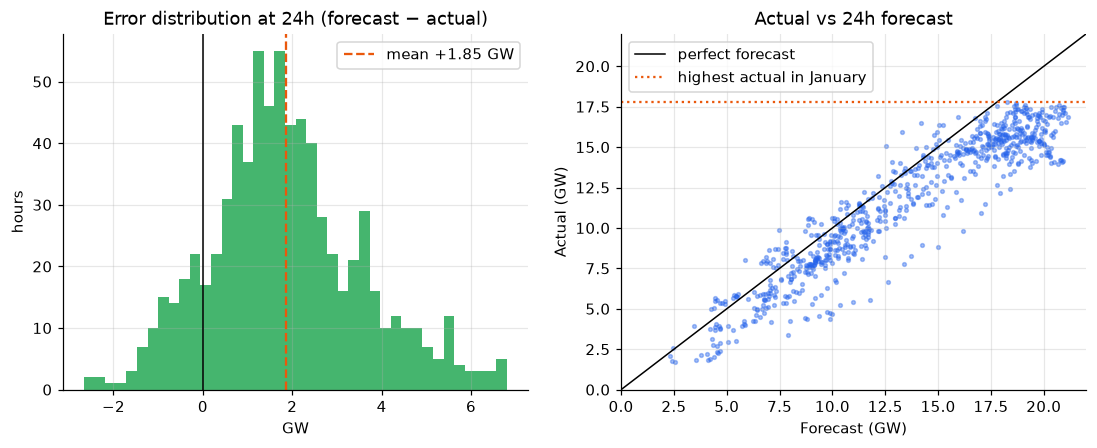

In [5]:
err = c24["error"]
share_over = (err > 0).mean()
print(f"At 24h the forecast was too high in {share_over:.0%} of hours; mean error {gw(err.mean()):+.2f} GW, "
      f"median {gw(err.median()):+.2f} GW.")
key_numbers["h24_share_hours_over_forecast_pct"] = round(share_over * 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.hist(gw(err), bins=40, color=COLORS["forecast"], alpha=0.8)
ax1.axvline(0, color="k", lw=1)
ax1.axvline(gw(err.mean()), color=COLORS["p90"], ls="--", label=f"mean {gw(err.mean()):+.2f} GW")
ax1.set(title="Error distribution at 24h (forecast − actual)", xlabel="GW", ylabel="hours")
ax1.legend()

ax2.scatter(gw(c24["forecast"]), gw(c24["actual"]), s=6, alpha=0.4, color=COLORS["actual"])
lim = [0, 22]
ax2.plot(lim, lim, color="k", lw=1, label="perfect forecast")
ax2.axhline(gw(actuals["generation"].max()), color=COLORS["p90"], ls=":", label="highest actual in January")
ax2.set(title="Actual vs 24h forecast", xlabel="Forecast (GW)", ylabel="Actual (GW)", xlim=lim, ylim=lim)
ax2.legend(loc="upper left");

In [6]:
# Is the over-forecast constant, or does it depend on how windy it is forecast to be?
bins = pd.cut(gw(c24["forecast"]), [0, 5, 10, 15, 20, 25])
by_level = c24.groupby(bins, observed=True).agg(
    hours=("error", "size"), bias_gw=("error", lambda s: gw(s.mean())),
    actual_as_pct_of_forecast=("actual", lambda s: 100 * s.sum() / c24.loc[s.index, "forecast"].sum()),
).round(1)
by_level.index = by_level.index.astype(str).rename("forecast level (GW)")
display(by_level)
print(f"Highest actual: {gw(actuals['generation'].max()):.1f} GW; highest forecast: {gw(forecasts['generation'].max()):.1f} GW")
key_numbers["h24_bias_when_forecast_over_20gw_gw"] = by_level["bias_gw"].iloc[-1]

,hours,bias_gw,actual_as_pct_of_forecast
forecast level (GW),,,
"(0, 5]",34,0.7,82.8
"(5, 10]",185,1.0,87.3
"(10, 15]",205,1.2,90.1
"(15, 20]",274,2.6,85.6
"(20, 25]",46,4.6,77.6


Highest actual: 17.8 GW; highest forecast: 21.4 GW


**Takeaway.** The forecast was too high in **87% of hours**, and the gap grows with how windy it is forecast
to be. Below 15 GW, actual wind is 83–90% of the forecast. When the forecast is above 20 GW, only **78%**
arrives, a shortfall of **4.6 GW** on average. Actual national wind **never exceeded 17.8 GW** in January, while
forecasts reached 21.4 GW; in the scatter plot, actuals level off below that line.

That pattern is consistent with a ceiling on the output this dataset records. Possible causes are wind farms
being curtailed or constrained off when the grid can't take their power, or the forecast covering capacity that
FUELHH does not report. **We have not verified the cause**, which would need constraint/balancing data. For a
buyer the cause matters less than the fact that the pattern is **systematic and therefore correctable**.

## 5. When are errors largest?

Worst hour 05:00 (MAE 2.51 GW), best 16:00 (MAE 1.68 GW).
Correlation of hourly MAE with mean actual wind: -0.67


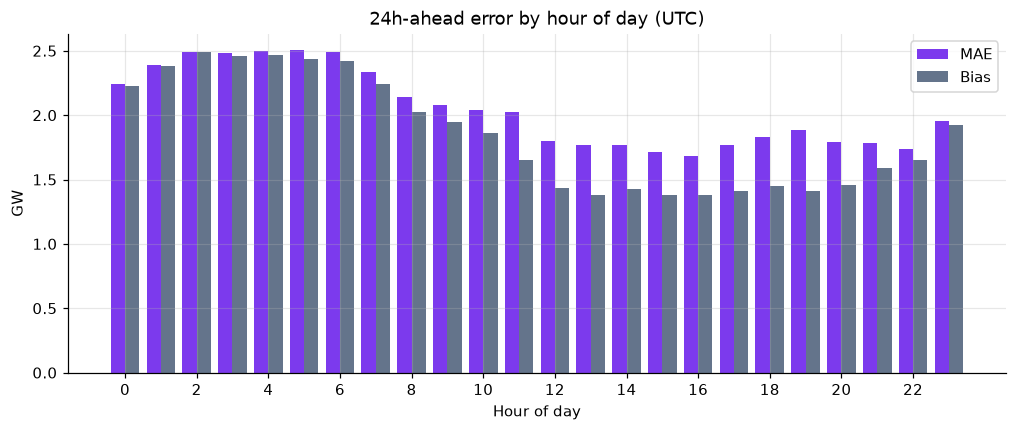

In [7]:
by_hour = c24.groupby(c24["startTime"].dt.hour).agg(
    mae=("error", lambda s: s.abs().mean()), bias=("error", "mean"), actual=("actual", "mean"))
fig, ax = plt.subplots()
ax.bar(by_hour.index - 0.2, gw(by_hour["mae"]), width=0.4, color=COLORS["mae"], label="MAE")
ax.bar(by_hour.index + 0.2, gw(by_hour["bias"]), width=0.4, color=COLORS["bias"], label="Bias")
ax.set(title="24h-ahead error by hour of day (UTC)", xlabel="Hour of day", ylabel="GW", xticks=range(0, 24, 2))
ax.legend();
print(f"Worst hour {by_hour['mae'].idxmax():02d}:00 (MAE {gw(by_hour['mae'].max()):.2f} GW), "
      f"best {by_hour['mae'].idxmin():02d}:00 (MAE {gw(by_hour['mae'].min()):.2f} GW).")
print(f"Correlation of hourly MAE with mean actual wind: {by_hour['mae'].corr(by_hour['actual']):.2f}")

Worst five days:


,mae_gw,bias_gw,mean_actual_gw,mean_forecast_gw
startTime,,,,
2026-01-11,5.02,5.02,13.51,18.53
2026-01-12,4.27,4.26,14.45,18.71
2026-01-01,4.27,4.27,15.36,19.63
2026-01-21,3.85,3.85,15.71,19.56
2026-01-28,3.68,3.68,5.81,9.49


Largest single-hour misses:


,startTime,publishTime,actual,forecast,error
530,2026-01-12 01:00:00+00:00,2026-01-10 22:30:00+00:00,14.05,20.85,6.80
532,2026-01-12 02:00:00+00:00,2026-01-10 22:30:00+00:00,14.12,20.88,6.76
528,2026-01-12 00:00:00+00:00,2026-01-10 22:30:00+00:00,13.95,20.66,6.70
534,2026-01-12 03:00:00+00:00,2026-01-11 02:30:00+00:00,14.17,20.82,6.65
536,2026-01-12 04:00:00+00:00,2026-01-11 02:30:00+00:00,14.19,20.76,6.57


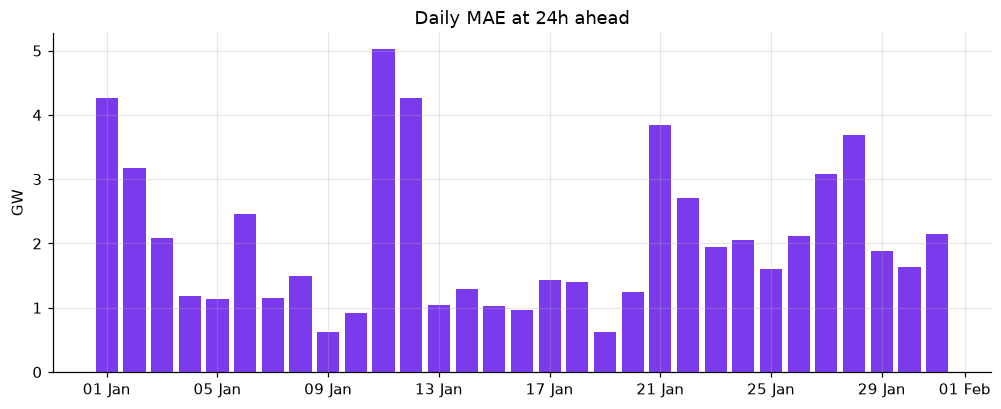

In [8]:
daily = c24.groupby(c24["startTime"].dt.date).agg(
    mae_gw=("error", lambda s: gw(s.abs().mean())), bias_gw=("error", lambda s: gw(s.mean())),
    mean_actual_gw=("actual", lambda s: gw(s.mean())), mean_forecast_gw=("forecast", lambda s: gw(s.mean())),
).round(2)

fig, ax = plt.subplots()
ax.bar(pd.to_datetime(daily.index), daily["mae_gw"], color=COLORS["mae"])
ax.set(title="Daily MAE at 24h ahead", ylabel="GW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

print("Worst five days:")
display(daily.sort_values("mae_gw", ascending=False).head(5))
print("Largest single-hour misses:")
worst = c24.reindex(c24["error"].abs().sort_values(ascending=False).index).head(5)
display(worst.assign(actual=gw(worst["actual"]).round(2), forecast=gw(worst["forecast"]).round(2),
                     error=gw(worst["error"]).round(2))
        [["startTime", "publishTime", "actual", "forecast", "error"]])

**Takeaway.** The worst days are dominated by the over-forecast. On **11 January** the forecast expected
18.5 GW on average and 13.5 GW arrived, a **5 GW shortfall all day**. The biggest single misses (about
**6.8 GW**) came in the early hours of 12 January, from forecasts made on the evening of 10 January. Four of the
five worst days had forecasts near 19 GW; the exception, **28 January**, was a genuine low-wind miss (9.5 GW
forecast, 5.8 GW actual). By time of day, errors were largest around 05:00 (2.5 GW) and smallest around
16:00 (1.7 GW). With one month of data this pattern is indicative only, and not something to plan around yet.

## 6. Recommendation: how much margin to hold?

Two ways to size the margin:

1. **Buffer on the raw forecast.** Plan for wind to come in short by the one-sided P90 (or P95) shortfall.
2. **Correct the bias first, then buffer.** Because the forecast is systematically high, scale it down and
   hold a smaller buffer for the remaining noise. To avoid fooling ourselves, the correction is **fitted on
   1–15 January and tested on 16–31 January**.

In [9]:
def shortfall_quantiles(error):
    """One-sided: how much LESS wind than planned arrived (positive = short)."""
    return {"P90": error.quantile(0.9), "P95": error.quantile(0.95)}

rows = {}
for h in (12, DAY_AHEAD_H, 36):
    q = shortfall_quantiles(comparison(h)["error"])
    rows[f"{h}h"] = {"P90 shortfall (GW)": gw(q["P90"]), "P95 shortfall (GW)": gw(q["P95"])}
display(pd.DataFrame(rows).round(2))

# Out-of-sample check of a simple multiplicative correction at 24h.
split = pd.Timestamp("2026-01-16T00:00Z")
train, test = c24[c24["startTime"] < split], c24[c24["startTime"] >= split]
ratio = train["actual"].sum() / train["forecast"].sum()  # adjusted forecast = ratio * forecast
test_err_raw = test["forecast"] - test["actual"]
test_err_adj = ratio * test["forecast"] - test["actual"]

oos = pd.DataFrame({
    "raw forecast": {"MAE": test_err_raw.abs().mean(), "bias": test_err_raw.mean(),
                     "P90 shortfall": test_err_raw.quantile(0.9), "P95 shortfall": test_err_raw.quantile(0.95)},
    f"forecast × {ratio:.3f}": {"MAE": test_err_adj.abs().mean(), "bias": test_err_adj.mean(),
                               "P90 shortfall": test_err_adj.quantile(0.9), "P95 shortfall": test_err_adj.quantile(0.95)},
}).pipe(gw).round(2)
print(f"Correction fitted on 1–15 Jan: actual wind = {ratio:.1%} of the 24h forecast. Evaluated on 16–31 Jan (GW):")
display(oos)

key_numbers.update(
    h24_p90_shortfall_gw=round(gw(c24["error"].quantile(0.9)), 2),
    h24_p95_shortfall_gw=round(gw(c24["error"].quantile(0.95)), 2),
    correction_ratio=round(ratio, 3),
    test_mae_raw_gw=oos.loc["MAE", "raw forecast"], test_mae_adjusted_gw=oos.iloc[0, 1],
    test_p90_shortfall_raw_gw=oos.loc["P90 shortfall", "raw forecast"],
    test_p90_shortfall_adjusted_gw=oos.iloc[2, 1],
)

,12h,24h,36h
P90 shortfall (GW),3.90,4.13,4.26
P95 shortfall (GW),4.59,5.10,5.42


Correction fitted on 1–15 Jan: actual wind = 86.6% of the 24h forecast. Evaluated on 16–31 Jan (GW):


,raw forecast,forecast × 0.866
MAE,2.02,0.89
bias,1.92,0.10
P90 shortfall,3.57,1.23
P95 shortfall,4.38,1.99


**Which plan is better for the buyer?** Both rules below are sized on 1–15 January to cover 90% of hours, then
applied unchanged to 16–31 January. *Planned wind* is the wind volume we assume when buying; if actual wind falls
below it we are short, and if actual wind exceeds it we bought power we didn't need.

In [10]:
def evaluate_plan(planned_mw, actual_mw):
    gap = actual_mw - planned_mw
    return {"hours short (%)": 100 * (gap < 0).mean(),
            "avg shortfall when short (GW)": gw(-gap[gap < 0].mean()) if (gap < 0).any() else 0.0,
            "avg excess power bought (GW)": gw(gap.clip(lower=0).mean())}

buffer_raw = (train["forecast"] - train["actual"]).quantile(0.9)
buffer_adj = (ratio * train["forecast"] - train["actual"]).quantile(0.9)
plans = pd.DataFrame({
    f"A: forecast − {gw(buffer_raw):.2f} GW": evaluate_plan(test["forecast"] - buffer_raw, test["actual"]),
    f"B: {ratio:.3f} × forecast − {gw(buffer_adj):.2f} GW": evaluate_plan(ratio * test["forecast"] - buffer_adj, test["actual"]),
}).round(2)
display(plans)

excess_saving = plans.iloc[2, 0] - plans.iloc[2, 1]
print(f"Plan B buys {excess_saving:.2f} GW less unneeded power on average "
      f"(≈ {excess_saving * 24:.0f} GWh per day) at a similar level of protection.")
key_numbers.update(
    plan_a_buffer_gw=round(gw(buffer_raw), 2), plan_b_buffer_gw=round(gw(buffer_adj), 2),
    plan_a_hours_short_pct=plans.iloc[0, 0], plan_b_hours_short_pct=plans.iloc[0, 1],
    plan_a_avg_excess_gw=plans.iloc[2, 0], plan_b_avg_excess_gw=plans.iloc[2, 1],
)

,A: forecast − 4.61 GW,B: 0.866 × forecast − 2.34 GW
hours short (%),4.17,3.91
avg shortfall when short (GW),0.64,1.21
avg excess power bought (GW),2.72,2.29


Plan B buys 0.43 GW less unneeded power on average (≈ 10 GWh per day) at a similar level of protection.


In [11]:
key_numbers = {k: (round(float(v), 3) if isinstance(v, (float, np.floating)) else int(v)) for k, v in key_numbers.items()}
(ROOT / "analysis" / "key_numbers.json").write_text(json.dumps(key_numbers, indent=2) + "\n")
pd.Series(key_numbers, name="value").to_frame()

,value
actual_min_gw,1.700
actual_mean_gw,11.580
actual_max_gw,17.800
actual_p10_gw,5.620
h24_mae_gw,2.050
h24_rmse_gw,2.520
h24_bias_gw,1.850
h24_p90_abs_gw,4.130
h24_mape_pct,20.500
mae_0h_gw,1.790


### Conclusions

1. **The forecast is biased, not just noisy.** At the 24h decision horizon it over-states wind by **1.85 GW**
   on average and is too high in **87%** of hours. The gap reaches **4.6 GW** when forecasts exceed 20 GW.
2. **Typical error at 24h is 2.05 GW (MAE), and 1 hour in 10 is off by 4.1 GW or more.** Error grows only
   **29%** between 0h and 42h ahead, so there is little to gain from deciding later within the day-ahead window.
3. **If we keep using the raw forecast,** plan for wind **4.1 GW below the forecast** to be covered 90% of the
   time at 24h (**5.1 GW** for 95%).
4. **A simple correction works out of sample.** Fitted on 1–15 January, actual wind ≈ **86.6% of the forecast**.
   Applied to 16–31 January it cut the typical error from **2.02 to 0.89 GW** and the 90th-percentile
   shortfall from **3.57 to 1.23 GW**.
5. **Recommended rule:** plan on **0.87 × forecast − ~2.3 GW** at the day-ahead stage. Tested on the second half
   of January it was short about as often as the raw-forecast rule (3.9% vs 4.2% of hours) while buying
   **0.43 GW less unnecessary power on average** (≈ 10 GWh/day). The trade-off: when it is short, it is short by
   more (1.2 vs 0.6 GW on average).
6. **Reliable wind floor:** in 90% of half-hours national wind was at least **5.6 GW**.

**Caveats.** One winter month only: the correction factor and buffers should be re-estimated on a rolling basis
(both rules were over-cautious in late January, short in ~4% of hours against a 10% target). The cause of the
bias is unverified, results are national wind only, and forecasts are matched hourly.